# Generative Forgery of Crowdsensed Sensor Streams: A Preliminary Evaluation of Trust Defenses
**Target:** IEEE PerCom 2027 Work-in-Progress (Goa) | **Deadline:** Nov 17, 2026 (23:59 AoE) | **Format:** 4 pages, IEEE two-column

**Research question.** Crowdsensing defenses (outlier filters, truth discovery, reputation) assume fake data is crude.
What happens when Sybil participants submit *generated* sensor streams that look like real sensors?

**Pipeline in this notebook**
1. Load honest participant streams (simulated from Beijing PM2.5 / synthetic, or *real* Delhi stations from the Kaggle India AQI dataset)
2. Build 5 forgers: white noise, replay, AR(1), VAE (learned generator), adaptive best-of-K VAE
3. Break 3 baseline defenses: MAD outlier filter, CRH-style truth discovery, reputation weighting
4. Our detector: 9 cheap features (intrinsic + consensus-coupled), supervised GBM and label-free IsolationForest
5. Sweeps: Sybil fraction, attacker proxy resolution, attack shift; figures + LaTeX table export

**Paper-level defaults:** `FAST=False`, 3 seeds, mean +/- std reporting, TPR@5%FPR, sweeps repeated over seeds with error bars, per-dataset output folders, latency measurement, LaTeX tables with +/- std. **Main experiment: `MODE="india_aqi"`** (real CPCB stations, Delhi). `MODE="simulated"` is optional: a controlled secondary check if page space allows. Set `FAST=True` only for a smoke test.

## 1. Install (EDIT: nothing; skip if offline)

In [1]:
%pip install -q ucimlrepo


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. Imports and configuration
**EDIT:** `MODE` (default "india_aqi" = main paper experiment; "simulated" = optional secondary check), `CITY`, `FAST`, `SEEDS`. For `india_aqi` on Kaggle, click *Add Data* and attach
`Air Quality Data in India (2015 - 2020)` (rohanrao). Files: `station_hour.csv` and (when available) `stations.csv`. This workspace bundle omits station metadata; the loader records and uses a `DL` StationId-prefix fallback for Delhi.

In [2]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats
from scipy.ndimage import uniform_filter1d
from sklearn.ensemble import GradientBoostingClassifier, IsolationForest
from sklearn.metrics import roc_auc_score, roc_curve
try:
    import torch, torch.nn as nn
    HAS_TORCH = True
except Exception:
    HAS_TORCH = False
    print("torch not found: the learned generator falls back to a numpy PCA generator (install torch for the VAE)")
warnings.filterwarnings("ignore")

FAST = False                      # True = smoke test only; paper numbers must come from FAST=False
SEEDS = [0] if FAST else [0, 1, 2]   # add 3, 4 for tighter error bars

CFG = dict(
    MODE="india_aqi",              # "india_aqi" (main, real data) | "simulated" (optional secondary)
    TRUTH_SOURCE="beijing",       # simulated mode: "beijing" (UCI) | "synthetic"
    INDIA_DIR=None,               # None = auto-detect Kaggle/local folder
    CITY="Delhi",
    INDIA_CHANNELS=["PM2.5", "PM10", "NO2", "CO", "SO2"],
    N_POOL=40,                    # simulated mode: number of honest sensors in the pool
    L=48,                         # window length in hours
    R=4,                          # windows per campaign (reputation needs R > 1)
    N_HONEST=20,                  # honest participants per campaign
    SYBIL_FRAC=0.3,               # fraction of ALL reports that are forged
    ATTACK_SHIFT=0.4,             # bias injected into attacked channels (std units)
    PROXY_NOISE=0.05,             # std of measurement noise on the attacker's proxy (0 = omniscient attacker)
    PROXY_SMOOTH=1,               # attacker capability: hours of smoothing in its public proxy (1 = real-time truth feed = strong attacker; 12-24 = weak)
    K_ADAPT=50,                   # best-of-K candidates for the adaptive attacker
    N_CAMP_TRAIN=30 if FAST else 150,
    N_CAMP_TEST=20 if FAST else 100,
    VAE_EPOCHS=15 if FAST else 60,
    N_VAE_SAMPLES=4000 if FAST else 20000,
)
OUT = f"outputs_{CFG['MODE']}"; os.makedirs(OUT, exist_ok=True)   # separate folder per dataset
print("torch:", torch.__version__ if HAS_TORCH else "not available", "| FAST =", FAST)

torch: 2.12.1 | FAST = False


## 3. Data layer
Three sources behind one interface that returns `streams [M sensors, T hours, C channels]` (standardised):
* **simulated** truth: Beijing PM2.5 from UCI (id 381) via `ucimlrepo`, falling back to a built-in synthetic series if offline; honest sensors are simulated with bias, AR(1) noise and level-dependent noise.
* **india_aqi**: *real* CPCB stations of one city act as honest participants (no simulated honest noise, a stronger story for reviewers).

**EDIT:** channels, `max_missing`, date range in `load_india_aqi`.

In [3]:
def _standardize(Z):
    return (Z - Z.mean(0)) / (Z.std(0) + 1e-9)

def synthetic_truth(T=24*365*2, C=5, seed=0):
    r = np.random.default_rng(seed); t = np.arange(T); X = np.zeros((T, C))
    for c in range(C):
        slow = signal.lfilter([1], [1, -0.98], r.standard_normal(T))
        fast = signal.lfilter([1], [1, -0.7], r.standard_normal(T))
        X[:, c] = (np.sin(2*np.pi*t/24 + r.uniform(0, 6.28)) + 0.5*np.sin(2*np.pi*t/168 + r.uniform(0, 6.28))
                   + 0.3*slow/np.std(slow) + 0.5*fast/np.std(fast))
    return _standardize(X), [f"ch{c}" for c in range(C)]

def load_beijing():
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=381)                       # Beijing PM2.5 Data (UCI)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)
    df.columns = [c.lower() for c in df.columns]
    df = df[["pm2.5", "dewp", "temp", "pres", "iws"]].astype(float)
    df = df.interpolate(limit=24, limit_direction="both").ffill().bfill()
    df["pm2.5"] = np.log1p(df["pm2.5"].clip(lower=0)); df["iws"] = np.log1p(df["iws"].clip(lower=0))
    return _standardize(df.values), ["PM2.5", "DEWP", "TEMP", "PRES", "Iws"]

def simulate_participants(truth, n, rng, ar=0.6, corr=0.4):
    T, C = truth.shape
    Cm = np.full((C, C), corr); np.fill_diagonal(Cm, 1.0); Lc = np.linalg.cholesky(Cm)
    out = np.zeros((n, T, C))
    for i in range(n):
        s = rng.uniform(0.08, 0.25, size=C); b = rng.normal(0, 0.08, size=C)
        eps = rng.standard_normal((T, C)) @ Lc.T
        e = signal.lfilter([1], [1, -ar], eps, axis=0) * np.sqrt(1 - ar**2)
        out[i] = truth + b + s * (1 + 0.25*np.abs(truth)) * e
    return out

def _find_india_dir():
    for p in ["/kaggle/input/air-quality-data-in-india", "./data/air-quality-data-in-india", "./data", "."]:
        if os.path.exists(os.path.join(p, "station_hour.csv")):
            return p
    raise FileNotFoundError("station_hour.csv not found. Attach the Kaggle dataset or set CFG['INDIA_DIR'].")

def load_india_aqi(base_dir, city, channels, min_stations=8, start="2018-01-01", end="2020-06-30", max_missing=0.25):
    global INDIA_STATION_MAPPING
    sh = pd.read_csv(os.path.join(base_dir, "station_hour.csv"), parse_dates=["Datetime"])
    station_meta = os.path.join(base_dir, "stations.csv")
    if os.path.exists(station_meta):
        st = pd.read_csv(station_meta)
        ids = st.loc[st["City"].astype(str).str.casefold() == city.casefold(), "StationId"].tolist()
        INDIA_STATION_MAPPING = "stations.csv City metadata"
    elif city.casefold() == "delhi":
        # This Kaggle bundle omits stations.csv. Delhi station IDs in station_hour.csv
        # use the DL prefix; select only IDs actually present in the supplied file.
        ids = sh.loc[sh["StationId"].astype(str).str.startswith("DL"), "StationId"].dropna().unique().tolist()
        INDIA_STATION_MAPPING = "StationId DL-prefix fallback (stations.csv absent)"
        print(f"stations.csv absent; selecting {len(ids)} observed DL-prefixed StationIds for Delhi")
    else:
        raise FileNotFoundError("stations.csv is required for city selection when the DL-prefix fallback does not apply")
    df = sh[sh["StationId"].isin(ids) & (sh["Datetime"] >= start) & (sh["Datetime"] <= end)]
    idx = pd.date_range(start, end, freq="h")
    mats = {}
    for sid, g in df.groupby("StationId"):
        g = g.drop_duplicates("Datetime").set_index("Datetime")[channels].reindex(idx)
        if g.isna().mean().mean() <= max_missing:
            g = g.interpolate(limit=12, limit_direction="both")
            g = g.fillna(g.median()).fillna(0.0)
            mats[sid] = g.values
    if len(mats) < min_stations:
        raise ValueError(f"Only {len(mats)} usable stations in {city}; raise max_missing, shorten dates, or pick another city.")
    S = np.log1p(np.clip(np.stack(list(mats.values())), 0, None))      # [M,T,C]
    train_end = max(1, int(0.6 * S.shape[1]))                         # match the existing temporal split
    flat_train = S[:, :train_end].reshape(-1, S.shape[-1])
    mu, sd = flat_train.mean(0), flat_train.std(0) + 1e-9
    return (S - mu) / sd, channels

def build_streams(cfg, seed=42):
    rng0 = np.random.default_rng(seed)
    if cfg["MODE"] == "india_aqi":
        S, names = load_india_aqi(cfg["INDIA_DIR"] or _find_india_dir(), cfg["CITY"], cfg["INDIA_CHANNELS"])
        return S, names, [0, 1]                                         # attack PM2.5 and PM10
    if cfg["TRUTH_SOURCE"] == "beijing":
        try: truth, names = load_beijing()
        except Exception as e:
            print("Beijing load failed, using synthetic truth instead:", repr(e)[:120]); truth, names = synthetic_truth()
    else:
        truth, names = synthetic_truth()
    return simulate_participants(truth, cfg["N_POOL"], rng0), names, [0]

## 4. Build the honest world and look at it
`streams[m, t, c]` are honest sensor readings. `cons_full` is the honest consensus (median over sensors). The attacker's *public proxy*
is a smoothed version of it (think delayed or low-resolution official feed). The default `PROXY_SMOOTH=1` is the *strong* attacker (real-time public feed); section 11C sweeps weaker attackers. The first 60% of time is "train" (attacker + detector training), the last 40% is "test".

**Sanity check:** the plot should show sensors that follow a shared signal with sensor-specific noise.

mode=india_aqi | sensors M=30 | hours T=21865 | channels=['PM2.5', 'PM10', 'NO2', 'CO', 'SO2'] | attacked=['PM2.5', 'PM10']


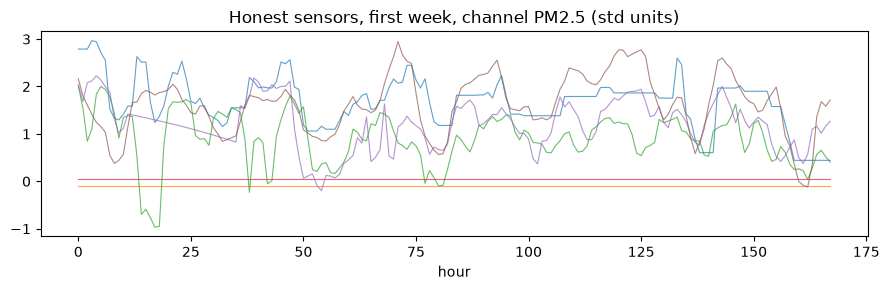

In [4]:
streams, CH_NAMES, ATTACK_CH = build_streams(CFG)
M, T, C = streams.shape
T_SPLIT = int(0.6 * T)
cons_full = np.median(streams, axis=0)

def make_proxy(k, noise=None):
    noise = CFG["PROXY_NOISE"] if noise is None else noise
    p = uniform_filter1d(cons_full, size=k, axis=0, mode="nearest") if k > 1 else cons_full.copy()
    return p + noise * np.random.default_rng(999).standard_normal(p.shape)

print(f"mode={CFG['MODE']} | sensors M={M} | hours T={T} | channels={CH_NAMES} | attacked={[CH_NAMES[i] for i in ATTACK_CH]}")
fig, ax = plt.subplots(figsize=(9, 3))
for i in range(min(6, M)): ax.plot(streams[i, :168, 0], lw=0.8, alpha=0.7)
ax.set_title(f"Honest sensors, first week, channel {CH_NAMES[0]} (std units)"); ax.set_xlabel("hour"); plt.tight_layout()
plt.savefig(f"{OUT}/fig0_honest.png", dpi=200); plt.show()

## 5. Features (the detector's inputs)
For each report stream we compute the residual `r = stream - leave-one-out consensus` and extract 9 features:
* **Intrinsic (sensor-realism):** lag-1 autocorrelation, spectral flatness, high-frequency power ratio, kurtosis, cross-channel residual correlation, heteroscedasticity (does noise grow with level?)
* **Consensus-coupled:** correlation of first differences with the consensus, residual RMSE, absolute bias

The intrinsic group is what a *generator* tries to imitate; the coupled group is what it cannot know without the real-time truth. The ablation in section 9 shows this.

In [5]:
FEAT_NAMES = ["ac1", "sflat", "hf", "kurt", "xch", "het", "fine_corr", "rmse", "bias_abs"]
IDX_INTRINSIC = [0, 1, 2, 3, 4, 5]
IDX_COUPLED = [6, 7, 8]
IDX_ALL = list(range(9))

def _lag1(r):
    a, b = r[:-1] - r[:-1].mean(0), r[1:] - r[1:].mean(0)
    return np.nanmean((a*b).sum(0) / (np.sqrt((a**2).sum(0) * (b**2).sum(0)) + 1e-12))

def resid_feats(r):
    # 5 intrinsic residual statistics, shape (5,)
    Cc = r.shape[1]
    f, p = signal.periodogram(r, axis=0, detrend="constant")
    p = p[1:] + 1e-12; ff = f[1:]
    sflat = np.mean(np.exp(np.log(p).mean(0)) / p.mean(0))
    hf = np.mean(p[ff > 0.25].sum(0) / p.sum(0))
    cm = np.corrcoef(r.T)
    xch = (np.nansum(np.abs(cm)) - Cc) / (Cc * (Cc - 1))
    return np.nan_to_num(np.array([_lag1(r), sflat, hf, np.mean(stats.kurtosis(r, axis=0)), xch]))

def window_features(rep):
    # rep: [N, L, C] reports in one window -> [N, 9] features
    N, L, Cc = rep.shape
    X = np.zeros((N, 9))
    for i in range(N):
        ref = np.median(np.delete(rep, i, axis=0), axis=0)
        r = rep[i] - ref
        het = np.nanmean([np.corrcoef(np.abs(r[:, c]), np.abs(ref[:, c]))[0, 1] for c in range(Cc)])
        ds, dr = np.diff(rep[i], axis=0), np.diff(ref, axis=0)
        fine = np.nanmean([np.corrcoef(ds[:, c], dr[:, c])[0, 1] for c in range(Cc)])
        X[i] = np.nan_to_num(np.r_[resid_feats(r), het, fine, np.sqrt((r**2).mean()), np.abs(r.mean(0)).mean()])
    return X

_t = time.time(); _ = window_features(streams[:20, :CFG["L"]]); LAT_WINDOW20_S = time.time() - _t
LAT_PER_STREAM_MS = 1000 * LAT_WINDOW20_S / 20
print(f"feature extraction ok: {LAT_WINDOW20_S:.2f}s per window of 20 streams = {LAT_PER_STREAM_MS:.1f} ms/stream (single CPU core; report this as the 'lightweight' claim)")

feature extraction ok: 0.01s per window of 20 streams = 0.5 ms/stream (single CPU core; report this as the 'lightweight' claim)


## 6. Forgers (the attack)
Every forged stream = **skeleton** (attacker's smoothed public proxy + `ATTACK_SHIFT` on attacked channels) + **generated sensor-like deviation**.
The forgers differ only in how they synthesise the deviation:

| name | how |
|---|---|
| `white` | Gaussian noise with matched per-channel std |
| `replay` | real recorded deviation windows from the public (train) period |
| `ar` | per-channel AR(1) with fitted coefficient |
| `vae` | MLP-VAE trained on honest deviation windows (learned generator; falls back to a PCA Gaussian generator if torch is missing) |
| `adaptive` | draw `K_ADAPT` VAE samples, keep the one whose intrinsic features are closest (Mahalanobis) to honest sensors |

**EDIT / stretch goal:** add a stronger forger (TimeGAN or a diffusion model) as another method with the same `sample(n, rng)` interface.

In [6]:
if HAS_TORCH:
    class _VAE(nn.Module):
        def __init__(self, D, z=16, h=256):
            super().__init__()
            self.enc = nn.Sequential(nn.Linear(D, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU())
            self.mu, self.lv = nn.Linear(h, z), nn.Linear(h, z)
            self.dec = nn.Sequential(nn.Linear(z, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, D))
        def forward(self, x):
            h = self.enc(x); mu, lv = self.mu(h), self.lv(h)
            z = mu + torch.randn_like(mu) * torch.exp(0.5 * lv)
            return self.dec(z), mu, lv

    class VAEGen:
        def __init__(self, D, epochs, z=16):
            n, L, Cc = D.shape; self.z, self.L, self.C = z, L, Cc
            self.sd = D.reshape(-1, Cc).std(0) + 1e-9
            X = torch.tensor((D / self.sd).reshape(n, L*Cc), dtype=torch.float32)
            self.net = _VAE(L*Cc, z); opt = torch.optim.Adam(self.net.parameters(), 1e-3)
            for ep in range(epochs):
                perm = torch.randperm(n)
                for b in range(0, n, 128):
                    xb = X[perm[b:b+128]]; rec, mu, lv = self.net(xb)
                    kl = (-0.5 * (1 + lv - mu**2 - lv.exp()).sum(1)).mean()
                    loss = ((rec - xb)**2).sum(1).mean() + 0.5 * kl
                    opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                rec, _, _ = self.net(X[:2000])
                self.obs_sd = (rec - X[:2000]).reshape(-1, L, Cc).std(0).numpy()      # per-timestep noise floor
        def sample(self, n, rng):
            with torch.no_grad():
                z = torch.tensor(rng.standard_normal((n, self.z)), dtype=torch.float32)
                mean = self.net.dec(z).reshape(n, self.L, self.C).numpy()
            return (mean + rng.standard_normal(mean.shape) * self.obs_sd) * self.sd
else:
    class VAEGen:
        # numpy fallback (linear Gaussian generator = probabilistic PCA) with the same interface as the VAE
        def __init__(self, D, epochs=None, z=16):
            n, L, Cc = D.shape; self.L, self.C = L, Cc
            self.sd = D.reshape(-1, Cc).std(0) + 1e-9
            X = (D / self.sd).reshape(n, L*Cc); self.mu = X.mean(0)
            U, S, Vt = np.linalg.svd(X - self.mu, full_matrices=False)
            var = S**2 / n; k = int(np.searchsorted(np.cumsum(var) / var.sum(), 0.95)) + 1
            self.W, self.lam = Vt[:k], np.sqrt(var[:k]); self.res = np.sqrt(max(var[k:].sum(), 1e-9) / (L*Cc))
        def sample(self, n, rng):
            z = rng.standard_normal((n, len(self.lam))) * self.lam
            x = z @ self.W + self.mu + rng.standard_normal((n, self.L*self.C)) * self.res
            return x.reshape(n, self.L, self.C) * self.sd

def sample_dev_windows(proxy, n, period, rng, L):
    lo, hi = period; out = np.empty((n, L, C))
    for j in range(n):
        i = rng.integers(M); t0 = rng.integers(lo, hi - L)
        out[j] = streams[i, t0:t0+L] - proxy[t0:t0+L]
    return out

class ForgerBank:
    def __init__(self, dev, epochs, rng, k_adapt):
        n, L, Cc = dev.shape; self.K = k_adapt
        self.means = dev.mean(1); dm = dev - self.means[:, None, :]
        self.dev, self.sd = dev, dm.reshape(-1, Cc).std(0)
        self.phi = np.clip(np.array([np.nanmean([_lag1(w[:, [c]]) for w in dm[:300]]) for c in range(Cc)]), 0, 0.99)
        self.vae = VAEGen(dev, epochs)
        hon = np.array([resid_feats(w) for w in dev[:1500]])
        self.mu = hon.mean(0); self.ic = np.linalg.pinv(np.cov(hon.T) + 1e-6*np.eye(hon.shape[1]))
        self.pool = self.vae.sample(3000, rng)
        d = np.array([resid_feats(w) for w in self.pool]) - self.mu
        self.pool_d = np.einsum("ij,jk,ik->i", d, self.ic, d)
    def sample(self, name, n, rng, L=None):
        L = L or self.dev.shape[1]; Cc = self.dev.shape[2]
        off = self.means[rng.integers(len(self.means), size=n)][:, None, :]
        if name == "white":  return rng.standard_normal((n, L, Cc)) * self.sd + off
        if name == "replay": return self.dev[rng.integers(len(self.dev), size=n)].copy()
        if name == "ar":
            eps = rng.standard_normal((n, L, Cc)) * self.sd * np.sqrt(1 - self.phi**2)
            ar = np.stack([signal.lfilter([1], [1, -self.phi[c]], eps[:, :, c], axis=1) for c in range(Cc)], axis=2)
            return ar + off
        if name == "vae":    return self.vae.sample(n, rng)
        if name == "adaptive":
            pick = [rng.integers(len(self.pool), size=self.K) for _ in range(n)]
            best = [c[np.argmin(self.pool_d[c])] for c in pick]
            return self.pool[best].copy()
        raise ValueError(name)

FORGERS = ["white", "replay", "ar", "vae", "adaptive"]
TRAIN_FORGERS = ["white", "replay", "ar"]     # detector never sees vae/adaptive in training (tests generalisation)

## 7. Campaign simulator and baseline defenses
A *campaign* = a fixed set of participants (honest sensors + Sybils) reporting over `R` consecutive windows.
**Baselines:** (1) MAD outlier filter per time step, (2) CRH-style truth discovery, (3) EMA reputation weighting.
**Metrics:** aggregate error on attacked channels (std units; lower is better) and stream-level AUROC (higher is better).

In [7]:
def make_campaign(fname, period, rng, bank, proxy, frac=None, shift=None, n_h=None):
    frac = CFG["SYBIL_FRAC"] if frac is None else frac
    shift = CFG["ATTACK_SHIFT"] if shift is None else shift
    n_h = min(n_h or CFG["N_HONEST"], M)
    S = int(round(frac / (1 - frac) * n_h)) if fname is not None else 0
    L, R = CFG["L"], CFG["R"]
    idx = rng.choice(M, size=n_h, replace=False)
    t0 = rng.integers(period[0], period[1] - R*L)
    wins, href = [], []
    for r in range(R):
        a = t0 + r*L; honest = streams[idx, a:a+L]
        if S > 0:
            skel = proxy[a:a+L].copy(); skel[:, ATTACK_CH] += shift
            rep = np.concatenate([honest, skel[None] + bank.sample(fname, S, rng, L)], 0)
        else:
            rep = honest
        wins.append(rep); href.append(honest.mean(0))
    return wins, np.r_[np.zeros(n_h), np.ones(S)], href

def d_mad(rep, k=3.0):
    med = np.median(rep, 0); mad = np.median(np.abs(rep - med), 0) * 1.4826 + 1e-6
    flag = np.abs(rep - med) / mad > k; w = (~flag).astype(float)
    return (rep * w).sum(0) / np.maximum(w.sum(0), 1), flag.mean((1, 2))

def d_truth(rep, iters=10):
    w = np.ones(len(rep)) / len(rep)
    for _ in range(iters):
        truth = (w[:, None, None] * rep).sum(0) / w.sum()
        err = ((rep - truth)**2).mean((1, 2)) + 1e-9
        w = np.maximum(-np.log(err / err.sum() + 1e-12), 1e-6)
    return (w[:, None, None] * rep).sum(0) / w.sum(), err / err.sum()

class Det:
    def __init__(self, kind, cols): self.kind, self.cols = kind, cols
    def score(self, X):
        Xs = X[:, self.cols]
        return self.m.predict_proba(Xs)[:, 1] if self.kind == "gbm" else -self.m.score_samples(Xs)
    def fit(self, X, y):
        Xs = X[:, self.cols]
        if self.kind == "gbm":
            self.m = GradientBoostingClassifier(n_estimators=120, max_depth=3, random_state=0).fit(Xs, y); self.thr = 0.5
        else:
            self.m = IsolationForest(n_estimators=200, random_state=0).fit(Xs[y == 0])
            self.thr = np.quantile(self.score(X[y == 0]), 0.95)
        return self

BASE = ["Mean (no defense)", "MAD filter", "Truth discovery", "Reputation"]
OURS = ["Ours: GBM (all)", "Ours: GBM (intrinsic)", "Ours: GBM (coupled)", "Ours: IsoForest (label-free)"]
METHODS = BASE + OURS

def run_methods(wins, href, dets):
    out = {m: {"err": [], "sc": []} for m in METHODS}; repu = None
    def put(m, agg, sc, r):
        out[m]["err"].append(np.abs(agg[:, ATTACK_CH] - href[r][:, ATTACK_CH]).mean()); out[m]["sc"].append(sc)
    for r, rep in enumerate(wins):
        N = len(rep)
        put("Mean (no defense)", rep.mean(0), np.zeros(N), r)
        a, s = d_mad(rep); put("MAD filter", a, s, r)
        a, s = d_truth(rep); put("Truth discovery", a, s, r)
        repu = np.ones(N) if repu is None else repu
        w = repu / repu.sum(); agg = (w[:, None, None] * rep).sum(0)
        err = np.sqrt(((rep - np.median(rep, 0))**2).mean((1, 2)))
        repu = 0.7*repu + 0.3*np.exp(-err / (np.median(err) + 1e-9)); put("Reputation", agg, 1 - repu/repu.max(), r)
        X = window_features(rep)
        for name, d in dets.items():
            sc = d.score(X); keep = sc <= d.thr
            put(name, rep[keep].mean(0) if keep.any() else rep.mean(0), sc, r)
    return out

## 8. Train our detectors (only on `white`, `replay`, `ar` forgers, train period)
* **GBM (all / intrinsic / coupled):** supervised; the intrinsic-only and coupled-only variants form the ablation.
* **IsoForest:** label-free, fitted on honest streams only (useful when you do not know the attacker).

The detector never sees `vae` or `adaptive` forgeries, so the test measures *generalisation to unseen generators*.

In [8]:
def build_train_set(names, n_camp, period, rng, bank, proxy):
    Xs, ys = [], []
    for k in range(n_camp):
        wins, lab, _ = make_campaign(names[k % len(names)], period, rng, bank, proxy)
        for rep in wins: Xs.append(window_features(rep)); ys.append(lab)
        if (k + 1) % 25 == 0: print(f"detector training campaigns: {k + 1}/{n_camp}")
    return np.vstack(Xs), np.concatenate(ys)

def fit_detectors(X, y):
    return {"Ours: GBM (all)": Det("gbm", IDX_ALL).fit(X, y),
            "Ours: GBM (intrinsic)": Det("gbm", IDX_INTRINSIC).fit(X, y),
            "Ours: GBM (coupled)": Det("gbm", IDX_COUPLED).fit(X, y),
            "Ours: IsoForest (label-free)": Det("iso", IDX_ALL).fit(X, y)}

def eval_forger(fname, n_camp, period, rng, bank, proxy, dets, frac=None, shift=None):
    errs = {m: [] for m in METHODS}; sc = {m: [] for m in METHODS}; lab_all = []
    for campaign_i in range(n_camp):
        wins, lab, href = make_campaign(fname, period, rng, bank, proxy, frac, shift)
        o = run_methods(wins, href, dets)
        for m in METHODS:
            errs[m].append(np.mean(o[m]["err"])); sc[m].append(np.concatenate(o[m]["sc"]))
        lab_all.append(np.tile(lab, len(wins)))
        if (campaign_i + 1) % 25 == 0: print(f"{fname} evaluation campaigns: {campaign_i + 1}/{n_camp}")
    y = np.concatenate(lab_all); res = {}
    for m in METHODS:
        s = np.concatenate(sc[m])
        ok = m != "Mean (no defense)" and y.sum() > 0
        tpr5 = float(np.interp(0.05, *roc_curve(y, s)[:2])) if ok else np.nan
        res[m] = (float(np.mean(errs[m])), roc_auc_score(y, s) if ok else np.nan, tpr5)
    return res

## 9. Main experiment
Runs every forger against every defense on the **test period** (never seen by the attacker or the detector).
Outputs: `results_main.csv`, mean +/- std table over seeds (AUROC, TPR@5%FPR, aggregate error), AUROC heatmap, feature importance averaged over seeds.

**What to look for:** (a) the baselines' aggregate error stays large against `vae`/`adaptive`; (b) AUROC of baselines near 0.5 for generative forgers;
(c) our detector keeps AUROC high, with the label-free variant as a robustness check; (d) intrinsic-only drops against `adaptive`, coupled features hold up.

In [9]:
def run_pipeline(seed):
    rng = np.random.default_rng(seed)
    if HAS_TORCH: torch.manual_seed(seed)
    proxy = make_proxy(CFG["PROXY_SMOOTH"])
    dev = sample_dev_windows(proxy, CFG["N_VAE_SAMPLES"], (0, T_SPLIT), rng, CFG["L"])
    bank = ForgerBank(dev, CFG["VAE_EPOCHS"], rng, CFG["K_ADAPT"])
    Xtr, ytr = build_train_set(TRAIN_FORGERS, CFG["N_CAMP_TRAIN"], (0, T_SPLIT), rng, bank, proxy)
    dets = fit_detectors(Xtr, ytr)
    rows = []
    for f in FORGERS:
        t = time.time(); res = eval_forger(f, CFG["N_CAMP_TEST"], (T_SPLIT, T), rng, bank, proxy, dets)
        for m, (e, a, t5) in res.items(): rows.append(dict(seed=seed, forger=f, method=m, agg_err=e, auroc=a, tpr5=t5))
        print(f"seed {seed} | forger {f:9s} done in {time.time()-t:.0f}s")
    return pd.DataFrame(rows), dict(bank=bank, proxy=proxy, dets=dets, rng=rng)

ART, frames = {}, []
for s in SEEDS:
    df_s, ART[s] = run_pipeline(s); frames.append(df_s)
RES = pd.concat(frames); RES.to_csv(f"{OUT}/results_main.csv", index=False)

def pivot(col, stat="mean"):
    return RES.pivot_table(index="method", columns="forger", values=col, aggfunc=stat, dropna=False).reindex(METHODS)[FORGERS]
def pm(col, d=2):
    mu, sd = pivot(col, "mean"), pivot(col, "std").fillna(0)
    return mu.round(d).astype(str) + " \u00b1 " + sd.round(d).astype(str)
TPR = pivot("tpr5")
AUC = RES.pivot_table(index="method", columns="forger", values="auroc", aggfunc="mean", dropna=False).reindex(METHODS)[FORGERS]
ERR = RES.pivot_table(index="method", columns="forger", values="agg_err", aggfunc="mean", dropna=False).reindex(METHODS)[FORGERS]
print(f"\nAUROC, mean \u00b1 std over {len(SEEDS)} seeds (higher = better detection)"); display(pm("auroc"))
print("TPR @ 5% FPR (higher = better)"); display(pm("tpr5"))
print("Aggregate error on attacked channels, std units (lower = better)"); display(pm("agg_err"))

detector training campaigns: 25/150


detector training campaigns: 50/150


detector training campaigns: 75/150


detector training campaigns: 100/150


detector training campaigns: 125/150


...

forger,white,replay,ar,vae,adaptive
method,,,,,
Mean (no defense),NaN,NaN,NaN,NaN,NaN
MAD filter,0.68 ± 0.01,0.64 ± 0.01,0.67 ± 0.01,0.68 ± 0.01,0.77 ± 0.01
Truth discovery,0.63 ± 0.01,0.59 ± 0.0,0.62 ± 0.0,0.61 ± 0.01,0.72 ± 0.01
Reputation,0.63 ± 0.0,0.6 ± 0.0,0.63 ± 0.0,0.62 ± 0.01,0.71 ± 0.01
Ours: GBM (all),1.0 ± 0.0,0.83 ± 0.0,0.98 ± 0.0,0.99 ± 0.0,0.96 ± 0.01
Ours: GBM (intrinsic),1.0 ± 0.0,0.77 ± 0.0,0.98 ± 0.0,0.99 ± 0.0,0.97 ± 0.01
Ours: GBM (coupled),0.81 ± 0.0,0.63 ± 0.01,0.78 ± 0.01,0.81 ± 0.01,0.75 ± 0.02
Ours: IsoForest (label-free),1.0 ± 0.0,0.52 ± 0.02,0.63 ± 0.03,0.99 ± 0.0,0.91 ± 0.01


TPR @ 5% FPR (higher = better)


forger,white,replay,ar,vae,adaptive
method,,,,,
Mean (no defense),NaN,NaN,NaN,NaN,NaN
MAD filter,0.07 ± 0.01,0.07 ± 0.01,0.07 ± 0.01,0.03 ± 0.01,0.1 ± 0.01
Truth discovery,0.04 ± 0.01,0.03 ± 0.0,0.03 ± 0.0,0.01 ± 0.0,0.02 ± 0.01
Reputation,0.01 ± 0.0,0.01 ± 0.0,0.01 ± 0.0,0.0 ± 0.0,0.01 ± 0.0
Ours: GBM (all),1.0 ± 0.0,0.33 ± 0.01,0.92 ± 0.0,0.95 ± 0.02,0.8 ± 0.05
Ours: GBM (intrinsic),1.0 ± 0.0,0.24 ± 0.01,0.91 ± 0.01,0.96 ± 0.0,0.83 ± 0.07
Ours: GBM (coupled),0.18 ± 0.02,0.12 ± 0.01,0.17 ± 0.01,0.21 ± 0.02,0.14 ± 0.03
Ours: IsoForest (label-free),1.0 ± 0.0,0.1 ± 0.01,0.08 ± 0.02,0.96 ± 0.0,0.49 ± 0.02


Aggregate error on attacked channels, std units (lower = better)


forger,white,replay,ar,vae,adaptive
method,,,,,
Mean (no defense),0.13 ± 0.0,0.13 ± 0.0,0.13 ± 0.0,0.14 ± 0.0,0.12 ± 0.01
MAD filter,0.26 ± 0.01,0.26 ± 0.01,0.25 ± 0.01,0.25 ± 0.01,0.24 ± 0.01
Truth discovery,0.17 ± 0.01,0.18 ± 0.01,0.18 ± 0.0,0.18 ± 0.01,0.15 ± 0.01
Reputation,0.14 ± 0.0,0.15 ± 0.0,0.14 ± 0.0,0.15 ± 0.0,0.13 ± 0.01
Ours: GBM (all),0.02 ± 0.0,0.12 ± 0.0,0.04 ± 0.0,0.03 ± 0.01,0.06 ± 0.01
Ours: GBM (intrinsic),0.02 ± 0.0,0.12 ± 0.0,0.04 ± 0.0,0.03 ± 0.0,0.06 ± 0.01
Ours: GBM (coupled),0.09 ± 0.0,0.13 ± 0.0,0.1 ± 0.01,0.09 ± 0.0,0.1 ± 0.0
Ours: IsoForest (label-free),0.01 ± 0.0,0.13 ± 0.0,0.13 ± 0.0,0.03 ± 0.0,0.1 ± 0.01


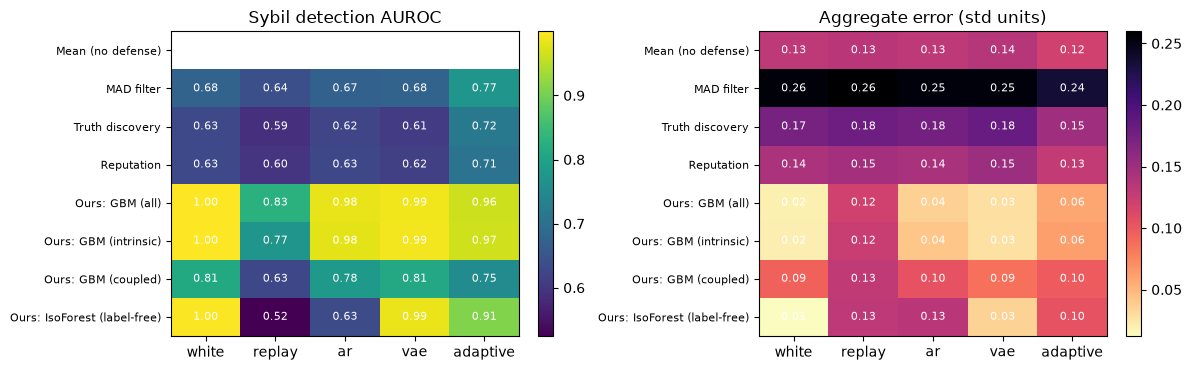

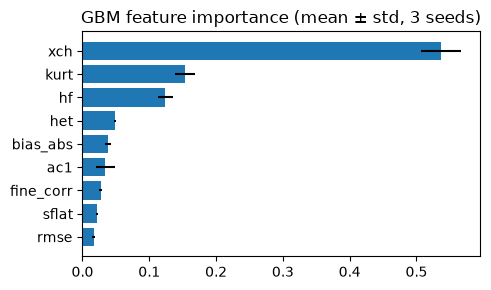

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, tab, ttl, cm in [(axs[0], AUC, "Sybil detection AUROC", "viridis"), (axs[1], ERR, "Aggregate error (std units)", "magma_r")]:
    im = ax.imshow(tab.values.astype(float), cmap=cm, aspect="auto")
    ax.set_xticks(range(len(FORGERS))); ax.set_xticklabels(FORGERS); ax.set_yticks(range(len(METHODS))); ax.set_yticklabels(METHODS, fontsize=8)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]; ax.text(j, i, "-" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", color="w", fontsize=8)
    ax.set_title(ttl); plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_main_heatmaps.png", dpi=200); plt.show()

IMP = pd.DataFrame({sd: ART[sd]["dets"]["Ours: GBM (all)"].m.feature_importances_ for sd in SEEDS}, index=FEAT_NAMES)
imp_m, imp_s = IMP.mean(1), IMP.std(1).fillna(0); order = imp_m.sort_values().index
fig, ax = plt.subplots(figsize=(5, 3)); ax.barh(order, imp_m[order], xerr=imp_s[order]); ax.set_title(f"GBM feature importance (mean \u00b1 std, {len(SEEDS)} seeds)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig2_feature_importance.png", dpi=200); plt.show()


## 10. Qualitative figure: what forged streams look like
One test window, attacked channel. Grey = honest sensors, red = forged. Use this as the paper's first figure.

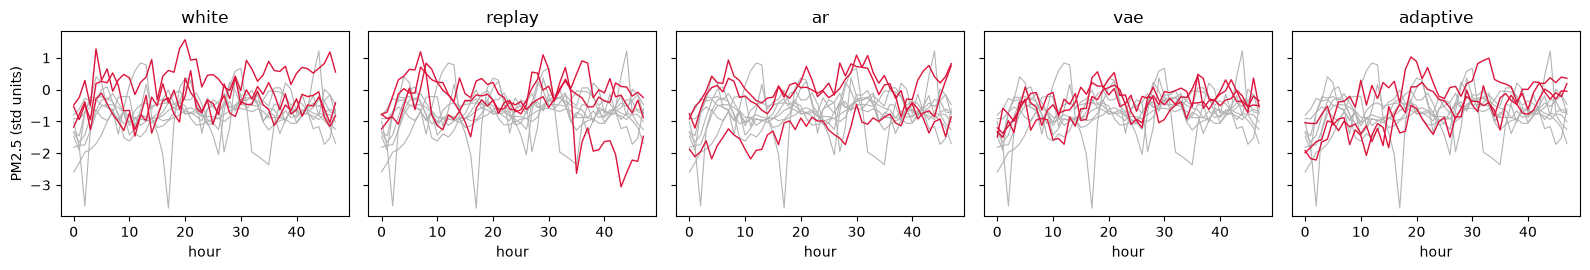

In [11]:
a0 = ART[SEEDS[0]]; rng_q = np.random.default_rng(123)
a = rng_q.integers(T_SPLIT, T - CFG["L"]); L = CFG["L"]
fig, axs = plt.subplots(1, 5, figsize=(16, 2.8), sharey=True)
for ax, f in zip(axs, FORGERS):
    for i in range(min(8, M)): ax.plot(streams[i, a:a+L, 0], color="0.7", lw=0.8)
    skel = a0["proxy"][a:a+L, 0] + CFG["ATTACK_SHIFT"]
    for g_ in a0["bank"].sample(f, 3, rng_q, L): ax.plot(skel + g_[:, 0], color="crimson", lw=1)
    ax.set_title(f); ax.set_xlabel("hour")
axs[0].set_ylabel(f"{CH_NAMES[0]} (std units)"); plt.tight_layout()
plt.savefig(f"{OUT}/fig3_forged_vs_honest.png", dpi=200); plt.show()

## 11. Sweeps (small, cheap, high value for the paper)
**A. Sybil fraction** -> aggregate error per defense (generative `vae` forger).
**B. Attack shift** -> stealth vs. impact: larger shifts hurt the aggregate more but are easier to detect.
**C. Attacker proxy resolution** -> how much real-time knowledge the attacker needs to defeat consensus-coupled features (k=1 means the attacker sees real-time truth).
**EDIT:** the lists below. The detector is kept fixed per seed (trained once at the default settings). Every sweep is repeated over all `SEEDS` and plotted as mean +/- std.

vae evaluation campaigns: 25/50


vae evaluation campaigns: 50/50


vae evaluation campaigns: 25/50


vae evaluation campaigns: 50/50


vae evaluation campaigns: 25/50


...

adaptive evaluation campaigns: 50/50


vae evaluation campaigns: 25/50


vae evaluation campaigns: 50/50


adaptive evaluation campaigns: 25/50


adaptive evaluation campaigns: 50/50
sweeps done for seed 2


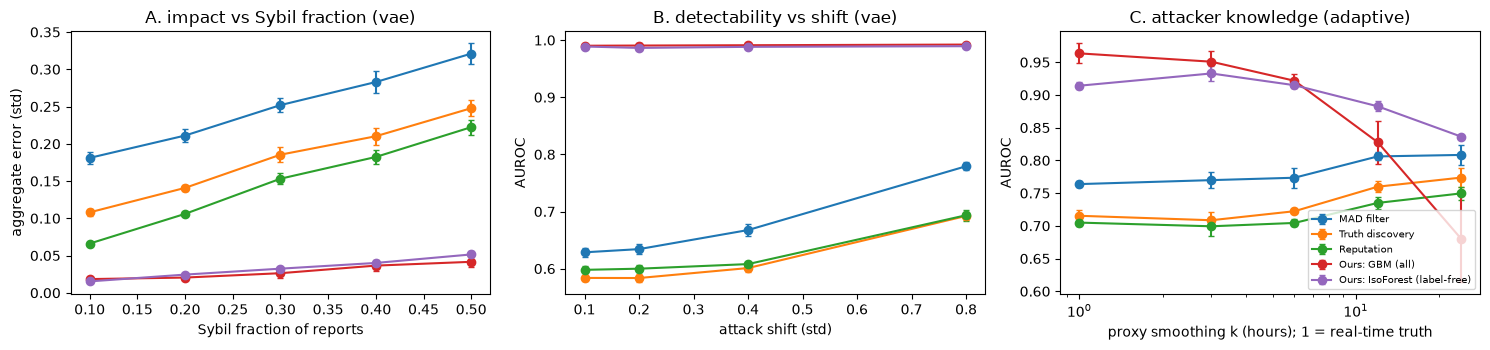

In [12]:
n_sw = max(8, CFG["N_CAMP_TEST"] // 2)
SHOW = ["MAD filter", "Truth discovery", "Reputation", "Ours: GBM (all)", "Ours: IsoForest (label-free)"]
rowsA, rowsB, rowsC = [], [], []
for sd in SEEDS:
    a0 = ART[sd]; rng_s = np.random.default_rng(777 + sd)
    if HAS_TORCH: torch.manual_seed(sd)
    for fr in [0.1, 0.2, 0.3, 0.4, 0.5]:                                  # A. Sybil fraction
        res = eval_forger("vae", n_sw, (T_SPLIT, T), rng_s, a0["bank"], a0["proxy"], a0["dets"], frac=fr)
        rowsA += [dict(seed=sd, frac=fr, method=m, agg_err=res[m][0], auroc=res[m][1], tpr5=res[m][2]) for m in METHODS]
    for sh in [0.1, 0.2, 0.4, 0.8]:                                       # B. attack shift
        res = eval_forger("vae", n_sw, (T_SPLIT, T), rng_s, a0["bank"], a0["proxy"], a0["dets"], shift=sh)
        rowsB += [dict(seed=sd, shift=sh, method=m, agg_err=res[m][0], auroc=res[m][1], tpr5=res[m][2]) for m in METHODS]
    for k in [1, 3, 6, 12, 24]:                                           # C. proxy resolution (retrains generator per k)
        proxy_k = make_proxy(k)
        dev_k = sample_dev_windows(proxy_k, CFG["N_VAE_SAMPLES"], (0, T_SPLIT), rng_s, CFG["L"])
        bank_k = ForgerBank(dev_k, CFG["VAE_EPOCHS"], rng_s, CFG["K_ADAPT"])
        for f in ["vae", "adaptive"]:
            res = eval_forger(f, n_sw, (T_SPLIT, T), rng_s, bank_k, proxy_k, a0["dets"])
            rowsC += [dict(seed=sd, k=k, forger=f, method=m, agg_err=res[m][0], auroc=res[m][1], tpr5=res[m][2]) for m in METHODS]
    print(f"sweeps done for seed {sd}")
A, B, Cdf = pd.DataFrame(rowsA), pd.DataFrame(rowsB), pd.DataFrame(rowsC)
A.to_csv(f"{OUT}/sweep_sybil_fraction.csv", index=False); B.to_csv(f"{OUT}/sweep_shift.csv", index=False); Cdf.to_csv(f"{OUT}/sweep_proxy_resolution.csv", index=False)

def band(ax, d, x, y, label):
    g = d.groupby(x)[y].agg(["mean", "std"]).fillna(0)
    ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=2, label=label)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for m in SHOW:
    band(axs[0], A[A.method == m], "frac", "agg_err", m)
    band(axs[1], B[B.method == m], "shift", "auroc", m)
    band(axs[2], Cdf[(Cdf.method == m) & (Cdf.forger == "adaptive")], "k", "auroc", m)
axs[0].set_xlabel("Sybil fraction of reports"); axs[0].set_ylabel("aggregate error (std)"); axs[0].set_title("A. impact vs Sybil fraction (vae)")
axs[1].set_xlabel("attack shift (std)"); axs[1].set_ylabel("AUROC"); axs[1].set_title("B. detectability vs shift (vae)")
axs[2].set_xlabel("proxy smoothing k (hours); 1 = real-time truth"); axs[2].set_ylabel("AUROC"); axs[2].set_xscale("log"); axs[2].set_title("C. attacker knowledge (adaptive)")
axs[2].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{OUT}/fig4_sweeps.png", dpi=200); plt.show()


## 12. Export for the paper
Writes LaTeX tables (AUROC, TPR@5%FPR, aggregate error, all as mean +/- std over seeds), `summary.json` (config, seeds, latency, versions) and the figures in the output folder.
**Before writing numbers into the paper:** confirm `FAST=False` in `summary.json`, and that `MODE="india_aqi"` was used for the main results (simulated is optional).


In [13]:
import json, sklearn, scipy
assert not FAST, "Set FAST=False and rerun before exporting paper numbers"
def to_tex(col, caption, label, d=2):
    mu, sd = pivot(col, "mean"), pivot(col, "std").fillna(0)
    t = mu.round(d).astype(str) + " $\\pm$ " + sd.round(d).astype(str)
    t = t.where(mu.notna(), "--")
    for f in FORGERS:                                                       # bold the best method per forger
        if mu[f].notna().any():
            b = mu[f].idxmin() if col == "agg_err" else mu[f].idxmax()
            t.loc[b, f] = "\\textbf{" + t.loc[b, f] + "}"
    with open(f"{OUT}/table_{col}.tex", "w") as fh:
        fh.write(t.to_latex(escape=False, caption=caption, label=label))
    with open(f"{OUT}/table_{col}_body.tex", "w") as fh:                    # tabular only, for \\resizebox{\\columnwidth}{!}{\\input{...}}
        fh.write(t.to_latex(escape=False))
to_tex("auroc", f"Sybil detection AUROC (mean $\\pm$ std, {len(SEEDS)} seeds).", "tab:auroc")
to_tex("tpr5", f"TPR at 5\\% FPR (mean $\\pm$ std, {len(SEEDS)} seeds).", "tab:tpr")
to_tex("agg_err", f"Aggregate error on attacked channels, std units (mean $\\pm$ std, {len(SEEDS)} seeds).", "tab:err")
json.dump({"mode": CFG["MODE"], "FAST": FAST, "sensors": int(M), "station_mapping": globals().get("INDIA_STATION_MAPPING", "not applicable"), "scaler_fit": "first 60% of timeline only", "hours": int(T), "channels": CH_NAMES, "seeds": SEEDS,
           "latency_ms_per_stream_feature_extraction": LAT_PER_STREAM_MS, "torch": HAS_TORCH,
           "versions": {"numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__, "scipy": scipy.__version__},
           "cfg": {k: (v if not isinstance(v, np.generic) else v.item()) for k, v in CFG.items()}},
          open(f"{OUT}/summary.json", "w"), indent=2, default=str)
print(sorted(os.listdir(OUT)))


['execute.log', 'execute_train_only.log', 'experiment_progress.log', 'fig0_honest.png', 'fig1_main_heatmaps.png', 'fig2_feature_importance.png', 'fig3_forged_vs_honest.png', 'fig4_sweeps.png', 'global_scaler_reference', 'results_main.csv', 'summary.json', 'sweep_proxy_resolution.csv', 'sweep_shift.csv', 'sweep_sybil_fraction.csv', 'sybil2_percom_wip_results.pdf', 'sybil2_percom_wip_results.tex', 'table_agg_err.tex', 'table_agg_err_body.tex', 'table_auroc.tex', 'table_auroc_body.tex', 'table_tpr5.tex', 'table_tpr5_body.tex']


## 13. Limitations to state in the paper (reviewers will ask)
* **Generator strength:** forgers are VAE-based; a TimeGAN/diffusion forger is future work (same `sample(n, rng)` interface plugs in).
* **Detector-aware attacker:** `adaptive` optimises only intrinsic-feature realism; an attacker that also targets the coupled features needs a real-time truth feed, which is exactly what sweep C quantifies.
* **Honest data:** main results use real CPCB stations from one city (Delhi), so state the single-city limit. There is no independent ground truth: the reference is the median of honest stations and the attacker's proxy is derived from it, so claims are about relative defense performance. `simulated` mode (optional) has a known truth but synthetic sensor noise.
* **Supervision:** the GBM trains on `white`/`replay`/`ar` only; `vae`/`adaptive` are unseen at training. The label-free IsolationForest is the fallback when attacker types are unknown.
* **Cost:** report `latency_ms_per_stream_feature_extraction` from `summary.json` for the lightweight claim (no hardware experiments).
